In [26]:
! git clone https://github.com/ahmed-roushdy16004392/data-engineering-project-1.git

fatal: destination path 'data-engineering-project-1' already exists and is not an empty directory.


In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as pxv
import os
os.listdir('/content/data-engineering-project-1/Data')

['council_districts.geojson',
 'housing_clean.csv',
 'crashes_clean.csv',
 'panel_district_year.csv',
 'Raw Data',
 'panel_borough_year.csv']

In [28]:
sns.set_theme(style="whitegrid", palette="Set2")

base_path = "/content/data-engineering-project-1/Data/"
# need c_web
c_web = pd.read_csv(base_path + "crashes_clean.csv")

# for q10
panel_b = pd.read_csv(base_path + "panel_borough_year.csv")

print("Borough Collumns:")
print(panel_b.columns.tolist())

print("\nCrash Collumns:")
print(c_web.columns.tolist())




Borough Collumns:
['borough_clean', 'year', 'crashes', 'fatal_crashes', 'fatalities', 'severe_injuries', 'building_records', 'affordable_units', 'new_units', 'preserved_units']

Crash Collumns:
['Collision ID', 'date_clean', 'year', 'weekday', 'hour', 'borough_clean', 'council_final', 'Latitude', 'Longitude', 'On Street', 'severity', 'Total Severe Injuries', 'Total Non-Severe Injuries', 'Total Fatalities', 'mass_casualty']


### Top 10 Streets with the Highest Number of Crashes

**Data used:** c_web (crashes_clean.csv)  
**Suggested chart:** Horizontal bar chart of the top 10 streets

/tmp/ipykernel_774/2354012876.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Crash Count', y='Street Name', data=top_streets, palette='viridis')


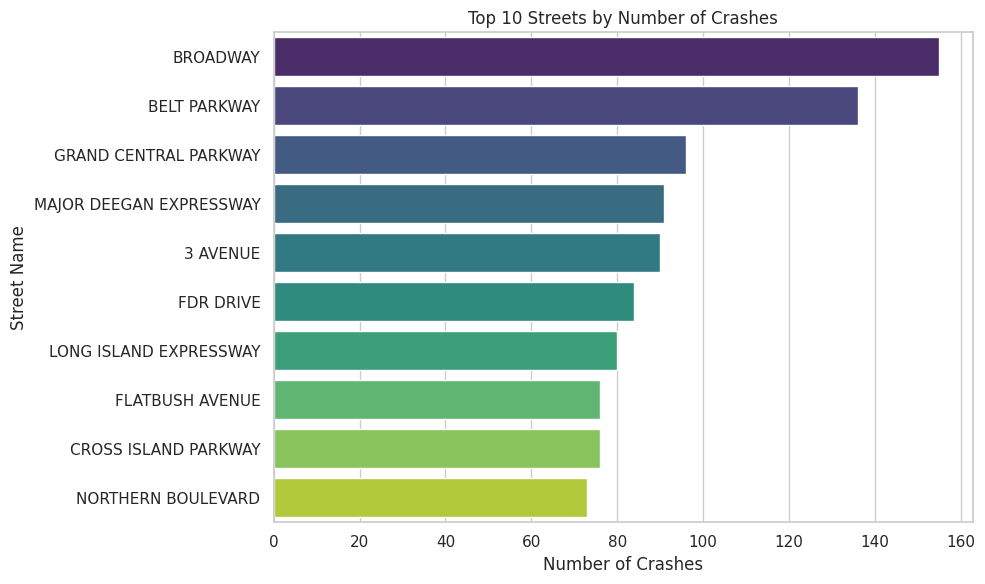

In [29]:
import matplotlib.pyplot as plt
import seaborn as sns

# Count crashes per street and select the top 10
top_streets = c_web['On Street'].value_counts().head(10).reset_index()
top_streets.columns = ['Street Name', 'Crash Count']

# Plotting the horizontal bar chart
plt.figure(figsize=(10, 6))
sns.barplot(x='Crash Count', y='Street Name', data=top_streets, palette='viridis')
plt.title('Top 10 Streets by Number of Crashes')
plt.xlabel('Number of Crashes')
plt.ylabel('Street Name')
plt.tight_layout()
plt.show()

**What the chart shows:** This chart shows that certain major public streets/highways are associated with a higher volume of reported traffic crashes than others. There is a visible concentration of incidents on certain high-traffic streets, with Broadway and Belt Parkway taking a significant lead.

**Limits:** This visualization represents absolute crash counts on each street and does not account for traffic volume or street length.

### Map of Building Records by NYC Council District


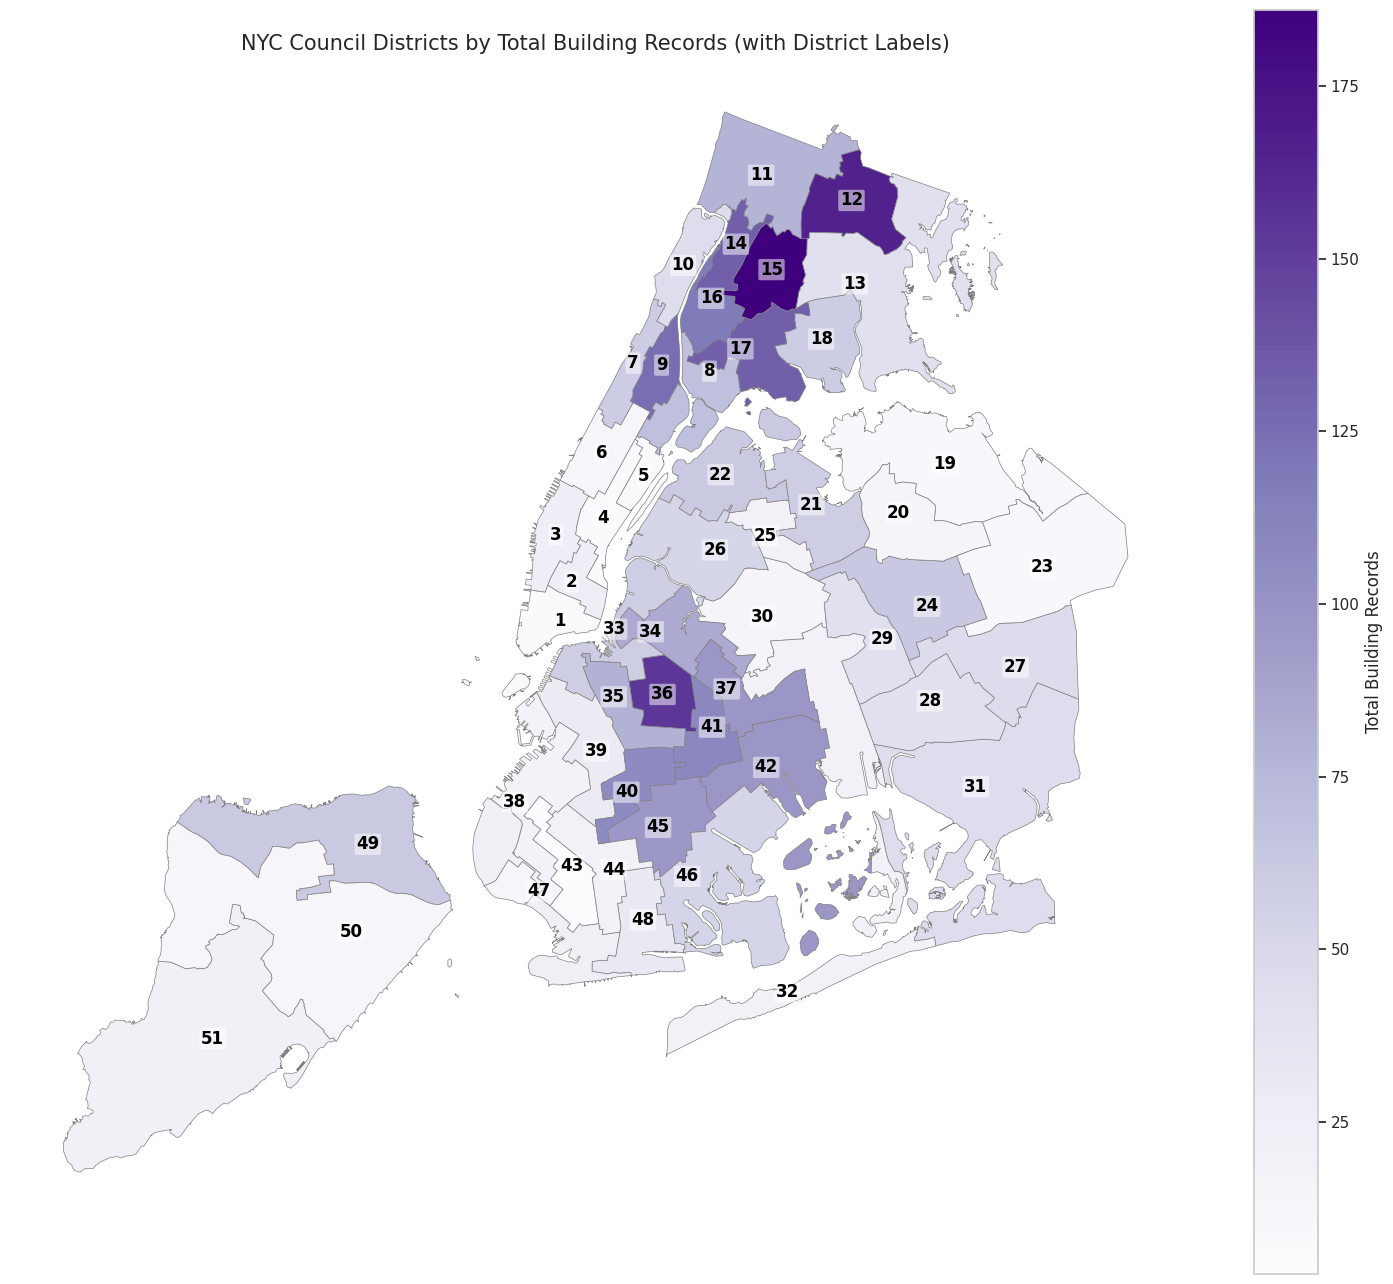

In [30]:
import geopandas as gpd
import matplotlib.pyplot as plt

geojson_path = "/content/data-engineering-project-1/Data/council_districts.geojson"
gdf = gpd.read_file(geojson_path)

council_col = [col for col in gdf.columns if 'coun' in col.lower()][0]
gdf[council_col] = gdf[council_col].astype(int)
district_totals = panel_d.groupby('council_final')['building_records'].sum().reset_index()
district_totals['council_final'] = district_totals['council_final'].astype(int)

#Merge
merged_gdf = gdf.merge(district_totals, left_on=council_col, right_on='council_final', how='left')
merged_gdf['building_records'] = merged_gdf['building_records'].fillna(0)

#plot
fig, ax = plt.subplots(1, 1, figsize=(15, 13))
merged_gdf.plot(
    column='building_records',
    cmap='Purples',
    linewidth=0.5,
    ax=ax,
    edgecolor='0.5',
    legend=True,
    legend_kwds={'label': 'Total Building Records'}
)

# Calculate representative points (centroids) for each council district to plot their numbers
for idx, row in merged_gdf.iterrows():
    # Using representative_point() instead of centroid because representative_point is guaranteed
    # to lie inside the geometry polygon (which is great for irregularly shaped districts)
    rep_point = row['geometry'].representative_point()
    x, y = rep_point.x, rep_point.y

    # Place the district number as a label
    ax.text(
        x, y,
        str(int(row['council_final'])),
        fontsize=12,
        fontweight='bold',
        ha='center',
        va='center',
        color='black',
        bbox=dict(facecolor='white', alpha=0.5, edgecolor='none', boxstyle='round,pad=0.1')
    )

ax.set_title('NYC Council Districts by Total Building Records (with District Labels)', fontsize=15)
ax.axis('off')
plt.tight_layout()
plt.show()

**What the map shows:** This choropleth map visually highlights the geographic distribution of building records across New York City council districts, with each region annotated with its respective district number. Specific clusters of districts (particularly Districts 15 and 12 in the Bronx, and District 36 in Brooklyn) show a higher spatial concentration of development activity.

**Limits:** This visualization displays absolute counts of building records within each district and does not adjust for the relative population sizes or geographic land areas of each district.